# Notebook 3 — Solutions to the exercises

Model solutions for instructors and self-learners. Try the exercises in `notebooks/03_compressed_sensing.ipynb` first.

## Setup (same as Notebook 3)

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from skimage.data import shepp_logan_phantom
from skimage.transform import resize

plt.rcParams["figure.dpi"] = 100
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # line colors, always used in this order

In [2]:
# ---- From Notebooks 1 and 2 ---------------------------------------------------
def fft2c(image):
    """Centered, orthonormal 2D FFT: image -> k-space."""
    return np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(image), norm="ortho"))


def ifft2c(kspace):
    """Centered, orthonormal inverse 2D FFT: k-space -> image."""
    return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(kspace), norm="ortho"))


def show(images, titles, cmap="gray", vmin=None, vmax=None):
    """Show images side by side."""
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(3.4 * n, 3.6))
    for ax, im, title in zip(np.atleast_1d(axes), images, titles):
        ax.set_title(title)
        if im.dtype == bool:  # sampling masks: white = measured, black = skipped, with a thin frame
            ax.imshow(im, cmap=cmap, vmin=0, vmax=1, interpolation="nearest")
            ax.set_xticks([])
            ax.set_yticks([])
        else:
            ax.imshow(im, cmap=cmap, vmin=vmin, vmax=vmax)
            ax.axis("off")
    plt.tight_layout()
    plt.show()


def nrmse(recon, reference):
    """Normalized root-mean-square error: 0 is perfect, 1 is as large as the image itself."""
    return np.linalg.norm(recon - reference) / np.linalg.norm(reference)


def tidy(ax):
    """Quiet grid and axes for line plots."""
    ax.grid(alpha=0.25, linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)


def regular_lines(N, R):
    """Every R-th phase-encode line, always including the center line."""
    lines = np.zeros(N, dtype=bool)
    lines[(N // 2) % R :: R] = True
    return lines


def variable_density_lines(N, R, center_fraction=0.08, decay=3, seed=0):
    """N // R lines: a fully sampled center, the rest random and more likely near the center."""
    rng = np.random.default_rng(seed)
    n_total = N // R
    n_center = int(round(N * center_fraction))
    lines = np.zeros(N, dtype=bool)
    lines[N // 2 - n_center // 2 : N // 2 - n_center // 2 + n_center] = True
    candidates = np.flatnonzero(~lines)
    distance = np.abs(candidates - N // 2) / (N / 2)
    probability = (1 - distance) ** decay + 1e-6
    lines[rng.choice(candidates, size=n_total - n_center, replace=False,
                     p=probability / probability.sum())] = True
    return lines


def as_mask(lines):
    """Turn a 1D set of phase-encode lines into a 2D k-space mask."""
    return np.repeat(lines[:, None], lines.size, axis=1)


def zero_filled(kspace, lines):
    """Treat unmeasured k-space as zero and apply the inverse FFT."""
    return np.abs(ifft2c(kspace * lines[:, None]))


# ---- The object and its fully sampled k-space ----------------------------------
N = 256
image = resize(shepp_logan_phantom(), (N, N), anti_aliasing=True)
kspace = fft2c(image)
print(f"Ground truth: {N} x {N} phantom")

Ground truth: 256 x 256 phantom


In [3]:
SQRT2 = np.sqrt(2)


def haar2(x, levels=4):
    """2D Haar wavelet transform: averages and differences of neighboring pixels, repeated `levels` times."""
    c = x.astype(complex).copy()
    n = c.shape[0]
    for _ in range(levels):
        a = c[:n, :n]
        a = np.hstack([(a[:, 0::2] + a[:, 1::2]) / SQRT2, (a[:, 0::2] - a[:, 1::2]) / SQRT2])  # along rows
        a = np.vstack([(a[0::2, :] + a[1::2, :]) / SQRT2, (a[0::2, :] - a[1::2, :]) / SQRT2])  # along columns
        c[:n, :n] = a
        n //= 2  # the next level works on the small "averages" image in the top-left corner
    return c


def ihaar2(c, levels=4):
    """Inverse of haar2: rebuilds the image exactly from its wavelet coefficients."""
    x = c.copy()
    n = x.shape[0] // 2 ** (levels - 1)
    for _ in range(levels):
        a = x[:n, :n]
        h = n // 2
        b = np.empty_like(a)
        b[0::2, :] = (a[:h, :] + a[h:, :]) / SQRT2
        b[1::2, :] = (a[:h, :] - a[h:, :]) / SQRT2
        a2 = np.empty_like(a)
        a2[:, 0::2] = (b[:, :h] + b[:, h:]) / SQRT2
        a2[:, 1::2] = (b[:, :h] - b[:, h:]) / SQRT2
        x[:n, :n] = a2
        n *= 2
    return x


def soft_threshold(c, lam):
    """Shrink every value towards zero by lam; values smaller than lam become exactly zero.
    Works for complex numbers: the magnitude shrinks, the phase stays."""
    magnitude = np.abs(c)
    return c * np.maximum(magnitude - lam, 0) / np.maximum(magnitude, 1e-12)


def cs_reconstruct(kspace_measured, lines, lam, n_iter=200, levels=4, reference=None):
    """Compressed sensing reconstruction with ISTA (iterative soft-thresholding).

    kspace_measured : k-space with unmeasured lines set to zero
    lines           : boolean array, True for measured phase-encode lines
    lam             : regularization weight (how strongly to enforce sparsity)
    reference       : optional ground truth, only used to record the error at each iteration
    """
    n = kspace_measured.shape[0]
    coarse = np.zeros((n, n), dtype=bool)          # the small "averages" image is not thresholded
    coarse[: n // 2**levels, : n // 2**levels] = True

    x = ifft2c(kspace_measured)                    # start from the zero-filled image
    history = []
    for _ in range(n_iter):
        # Step 1, data consistency: put the measured k-space lines back exactly
        k = fft2c(x)
        k = np.where(lines[:, None], kspace_measured, k)
        x = ifft2c(k)
        # Step 2, sparsity: soft-threshold the wavelet coefficients
        w = haar2(x, levels)
        w = np.where(coarse, w, soft_threshold(w, lam))
        x = ihaar2(w, levels)
        if reference is not None:
            history.append(nrmse(np.abs(x), reference))
    return x, history


def zoom(img):
    """The region with the three small ellipses near the bottom of the phantom."""
    return img[170:230, 90:170]

In [4]:
lines = variable_density_lines(N, R=4)
measured = kspace * lines[:, None]

## Exercise 1: another kind of sparsity

vertical differences below 0.001:   95.8%
horizontal differences below 0.001: 94.8%
Haar detail coefficients below 0.001: 92.0%


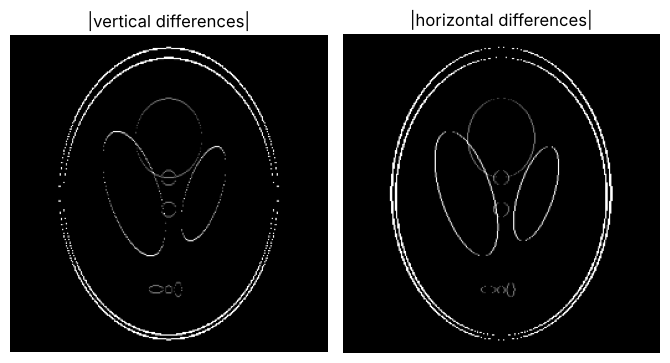

In [5]:
dy = np.diff(image, axis=0)
dx = np.diff(image, axis=1)
coeffs = haar2(image, levels=4)
detail = np.ones((N, N), dtype=bool)
detail[: N // 16, : N // 16] = False   # exclude the coarse averages

print(f"vertical differences below 0.001:   {np.mean(np.abs(dy) < 1e-3):.1%}")
print(f"horizontal differences below 0.001: {np.mean(np.abs(dx) < 1e-3):.1%}")
print(f"Haar detail coefficients below 0.001: {np.mean(np.abs(coeffs[detail]) < 1e-3):.1%}")
show([np.abs(dy), np.abs(dx)], ["|vertical differences|", "|horizontal differences|"], vmin=0, vmax=0.2)

The large majority of differences are essentially zero: the phantom is flat except along edges. Both representations are very sparse for this piecewise-constant phantom. Total variation (TV) regularization penalizes the sum of these differences instead of wavelet coefficients. It produces flat regions with sharp edges, without the square blocks of Haar wavelets, but can make real anatomy look "cartoon-like" when λ is too large.

## Exercise 2: is the result consistent with the measurements?

Relative mismatch on the measured lines: 2.02%
NRMSE, ISTA result:                 0.134
NRMSE, with final data consistency: 0.132


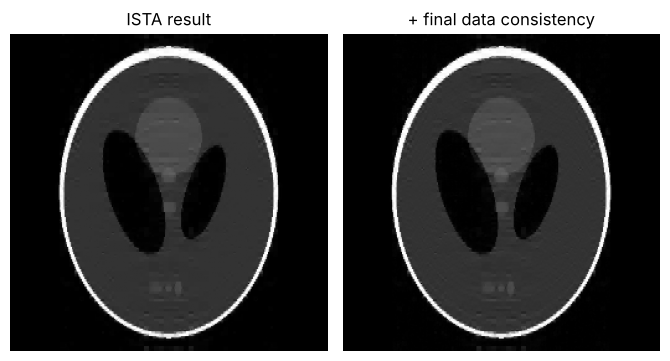

In [6]:
x, _ = cs_reconstruct(measured, lines, lam=0.01)
k_result = fft2c(x)
mismatch = np.linalg.norm(k_result[lines] - measured[lines]) / np.linalg.norm(measured[lines])
print(f"Relative mismatch on the measured lines: {mismatch:.2%}")

k_consistent = np.where(lines[:, None], measured, k_result)
x_consistent = ifft2c(k_consistent)
print(f"NRMSE, ISTA result:                 {nrmse(np.abs(x), image):.3f}")
print(f"NRMSE, with final data consistency: {nrmse(np.abs(x_consistent), image):.3f}")
show([np.abs(x), np.abs(x_consistent)], ["ISTA result", "+ final data consistency"], vmin=0, vmax=1)

The final soft-thresholding step changes the measured lines slightly. Putting them back makes the image agree exactly with what the scanner measured. The NRMSE changes only a little in either direction. A radiologist may prefer exact consistency because then everything in the measured data, including an unexpected finding the sparsity model "didn't like", is guaranteed to be represented in the image. Many deep learning methods (Notebook 4) end with such a data consistency step for the same reason.

## Exercise 3: the best mask depends on the reconstruction

In [7]:
print(f"{'mask':<18}{'zero-filled':>12}{'CS':>8}")
for decay in [3, 1]:
    l = variable_density_lines(N, 4, decay=decay)
    m = kspace * l[:, None]
    zf_err = nrmse(zero_filled(kspace, l), image)
    cs_err = nrmse(np.abs(cs_reconstruct(m, l, lam=0.01)[0]), image)
    print(f"{'decay = ' + str(decay):<18}{zf_err:>12.3f}{cs_err:>8.3f}")

mask               zero-filled      CS


decay = 3                0.293   0.134


decay = 1                0.361   0.128


With **zero-filling**, the default (decay 3) wins: it concentrates lines near the center, which carries most of the energy. With **compressed sensing**, decay 1 wins: it puts more random lines in the outer k-space, so it measures more fine detail, and the extra noise-like artifact is exactly what compressed sensing can remove. The best sampling pattern depends on the reconstruction method. In research, masks and reconstruction are increasingly designed (or even learned) together.

## Exercise 4: noisy measurements

λ = 0.001 : clean 0.209   noisy 0.249
λ = 0.002 : clean 0.172   noisy 0.227
λ = 0.005 : clean 0.135   noisy 0.206
λ = 0.01  : clean 0.134   noisy 0.199
λ = 0.02  : clean 0.152   noisy 0.194
λ = 0.03  : clean 0.169   noisy 0.192
λ = 0.05  : clean 0.190   noisy 0.199
λ = 0.1   : clean 0.227   noisy 0.229
best λ, clean: 0.01,  noisy: 0.03


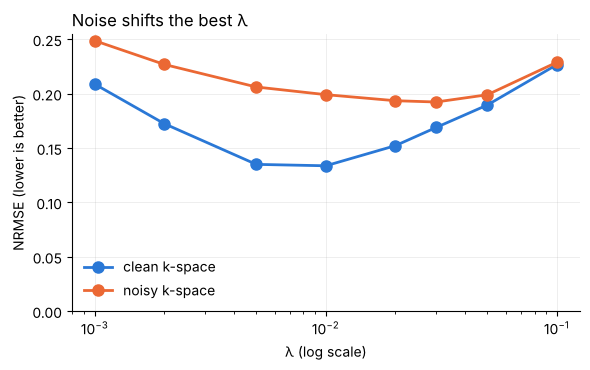

In [8]:
noise_rng = np.random.default_rng(0)
sigma = 0.05
noisy_kspace = kspace + sigma * (noise_rng.standard_normal((N, N)) + 1j * noise_rng.standard_normal((N, N))) / np.sqrt(2)
noisy_measured = noisy_kspace * lines[:, None]

lam_values = [0.001, 0.002, 0.005, 0.01, 0.02, 0.03, 0.05, 0.1]
clean_errors = [nrmse(np.abs(cs_reconstruct(measured, lines, lam)[0]), image) for lam in lam_values]
noisy_errors = [nrmse(np.abs(cs_reconstruct(noisy_measured, lines, lam)[0]), image) for lam in lam_values]

for lam, c, n in zip(lam_values, clean_errors, noisy_errors):
    print(f"λ = {lam:<6}: clean {c:.3f}   noisy {n:.3f}")
print(f"best λ, clean: {lam_values[int(np.argmin(clean_errors))]},  noisy: {lam_values[int(np.argmin(noisy_errors))]}")

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.semilogx(lam_values, clean_errors, "o-", color=COLORS[0], linewidth=2, markersize=8, label="clean k-space")
ax.semilogx(lam_values, noisy_errors, "o-", color=COLORS[1], linewidth=2, markersize=8, label="noisy k-space")
ax.set_xlabel("λ (log scale)")
ax.set_ylabel("NRMSE (lower is better)")
ax.set_title("Noise shifts the best λ", loc="left")
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
tidy(ax)
plt.tight_layout()
plt.show()

With noise, small λ values do worse, because the reconstruction now keeps the noise as well as the artifacts. The best λ moves to a larger value: soft-thresholding then removes noise too, acting as a denoiser. This is why λ must be tuned for each type of scan and noise level, one more practical burden that deep learning methods try to avoid.